<a href="https://colab.research.google.com/github/anseohyeonn/trash-classfication/blob/main/trash_classfication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ============================================================
# Stage 1. 라이브러리 설치 및 데이터 준비
# ============================================================

!pip -q install scikit-learn seaborn

import os
import time
import random
import zipfile
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.datasets import ImageFolder

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from PIL import Image
from collections import Counter

# ------------------------------------------------------------
# 1. 재현성을 위한 시드 고정
# ------------------------------------------------------------

SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("사용 장치:", device)

# ------------------------------------------------------------
# 2. 기본 환경 설정
# ------------------------------------------------------------

IS_COLAB = os.path.exists("/content")

if IS_COLAB:
    BASE_DIR = "/content"
else:
    BASE_DIR = "."

DATA_DIR = os.path.join(BASE_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)

RESULT_DIR = os.path.join(
    BASE_DIR,
    "garbage_classification_results"
)
os.makedirs(RESULT_DIR, exist_ok=True)

print("데이터 경로:", DATA_DIR)
print("결과 저장 경로:", RESULT_DIR)

# ------------------------------------------------------------
# 3. 클래스 폴더 탐색
# ------------------------------------------------------------

class_names = {
    "battery", "batteries", "biological",
    "cardboard", "clothes", "shoes",
    "green-glass", "brown-glass",
    "white-glass", "metal", "paper",
    "plastic", "trash"
}

def normalize_name(name):
    return name.lower().replace("_", "-").replace(" ", "-")

def find_data_dir(base_path):

    if not os.path.exists(base_path):
        return None

    for root, dirs, files in os.walk(base_path):

        normalized = {
            normalize_name(d) for d in dirs
        }

        if len(normalized & class_names) >= 12:
            return root

    return None

# ------------------------------------------------------------
# 4. 기존 데이터 확인
# ------------------------------------------------------------

DATASET = None
FOUND_DATA_DIR = find_data_dir(DATA_DIR)

if FOUND_DATA_DIR is not None:

    try:
        candidate = ImageFolder(FOUND_DATA_DIR)

        if len(candidate.classes) == 12 and len(candidate) > 0:
            DATASET = candidate

            print("기존 데이터셋 발견!")
            print("이미지 수:", len(DATASET))

    except Exception:
        DATASET = None

# ------------------------------------------------------------
# 5. 데이터가 없다면 ZIP 업로드
# ------------------------------------------------------------

if DATASET is None:

    zip_path = os.path.join(BASE_DIR, "archive.zip")

    if not os.path.exists(zip_path):

        if IS_COLAB:

            from google.colab import files

            print("Garbage Classification ZIP 파일을 업로드하세요.")

            uploaded = files.upload()

            zip_files = [
                name for name in uploaded.keys()
                if name.lower().endswith(".zip")
            ]

            if len(zip_files) == 0:
                raise FileNotFoundError(
                    "ZIP 파일이 업로드되지 않았습니다."
                )

            zip_path = os.path.join(BASE_DIR, zip_files[0])

        else:
            raise FileNotFoundError(
                "현재 폴더에 archive.zip 파일이 없습니다."
            )

    # ZIP 파일 이미지 개수 확인
    image_extensions = {
        ".jpg", ".jpeg", ".png",
        ".bmp", ".webp", ".tif", ".tiff"
    }

    with zipfile.ZipFile(zip_path, "r") as z:

        image_count = sum(
            Path(info.filename).suffix.lower() in image_extensions
            and "__MACOSX" not in Path(info.filename).parts
            and not Path(info.filename).name.startswith("._")
            for info in z.infolist()
            if not info.is_dir()
        )

    print("ZIP 내부 이미지 개수:", image_count)

    # 압축 해제
    print("압축 해제 시작...")

    start_time = time.time()

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(DATA_DIR)

    print("압축 해제 완료!")
    print("소요 시간:", round(time.time() - start_time, 2), "초")

    # 데이터 폴더 다시 탐색
    FOUND_DATA_DIR = find_data_dir(DATA_DIR)

    if FOUND_DATA_DIR is None:
        raise FileNotFoundError(
            "12개 클래스 폴더를 찾지 못했습니다. ZIP 구조를 확인하세요."
        )

    DATASET = ImageFolder(FOUND_DATA_DIR)

# ------------------------------------------------------------
# 6. 최종 데이터 확인
# ------------------------------------------------------------

classes = DATASET.classes

assert len(classes) == 12, "클래스 수가 12개가 아닙니다."
assert len(DATASET) > 0, "데이터가 없습니다."

print("\n" + "=" * 60)
print("Stage 1 데이터 준비 완료")
print("=" * 60)

print("사용 장치:", device)
print("데이터 경로:", FOUND_DATA_DIR)
print("클래스 수:", len(classes))
print("클래스 목록:", classes)
print("전체 이미지 수:", len(DATASET))


사용 장치: cuda
데이터 경로: /content/data
결과 저장 경로: /content/garbage_classification_results
Garbage Classification ZIP 파일을 업로드하세요.


Saving archive.zip to archive.zip
ZIP 내부 이미지 개수: 15515
압축 해제 시작...
압축 해제 완료!
소요 시간: 5.93 초

Stage 1 데이터 준비 완료
사용 장치: cuda
데이터 경로: /content/data/garbage_classification
클래스 수: 12
클래스 목록: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
전체 이미지 수: 15515


===== 클래스별 이미지 개수 =====
      Class  Image Count
    battery          945
 biological          985
brown-glass          607
  cardboard          891
    clothes         5325
green-glass          629
      metal          769
      paper         1050
    plastic          865
      shoes         1977
      trash          697
white-glass          775

전체 이미지: 15515
최소 클래스 이미지: 607
최대 클래스 이미지: 5325


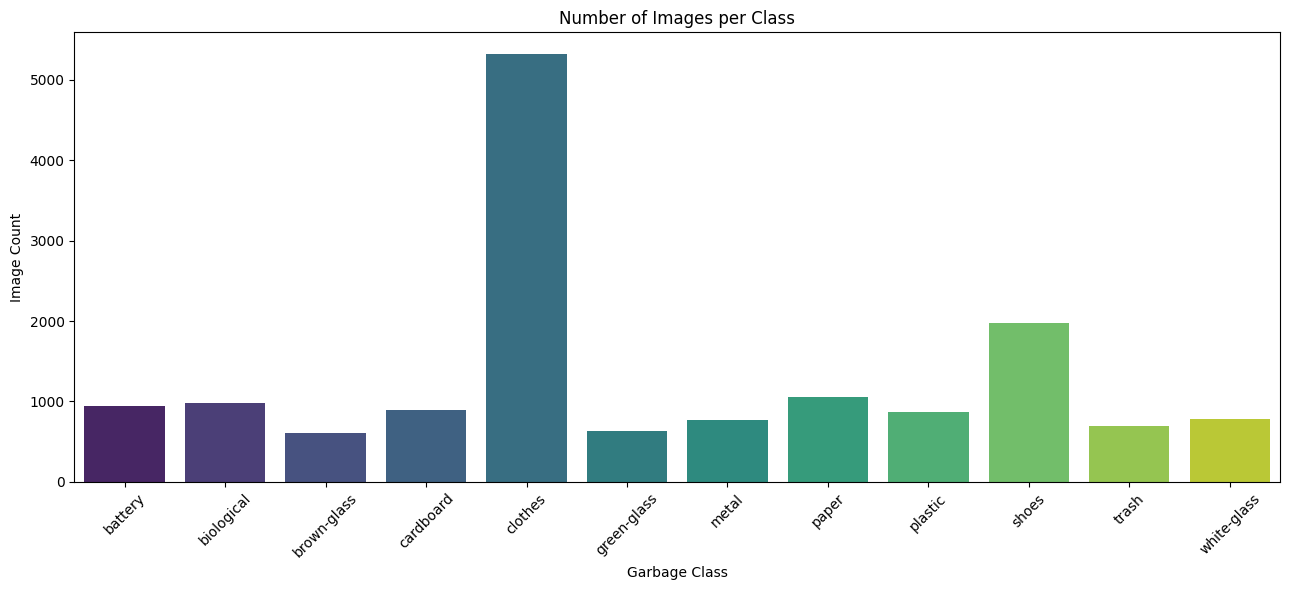

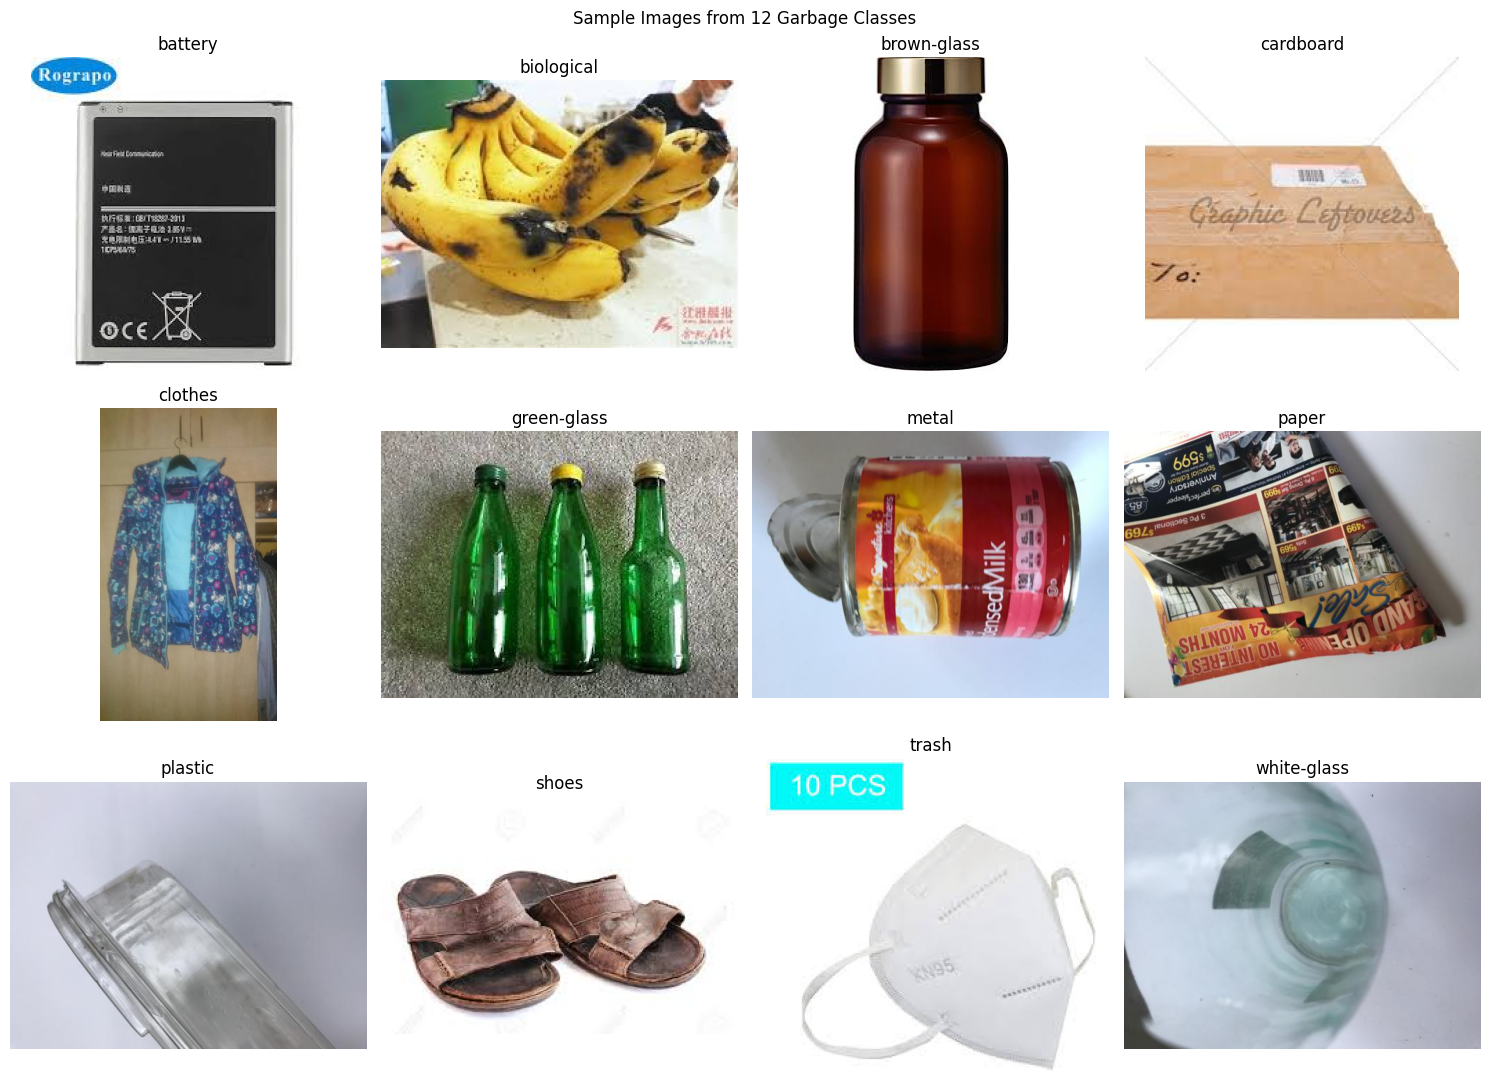


===== 원본 이미지 크기 상위 10개 =====
(400, 533) : 54
(512, 384) : 50
(225, 225) : 28
(400, 534) : 20
(275, 183) : 16
(194, 259) : 7
(259, 194) : 7
(533, 400) : 7
(400, 711) : 6
(534, 400) : 5

===== 데이터 분할 결과 =====
Train: 10860
Validation: 2327
Test: 2328
      Class  Train  Validation  Test
    battery    661         142   142
 biological    689         148   148
brown-glass    425          91    91
  cardboard    624         133   134
    clothes   3727         799   799
green-glass    440          95    94
      metal    538         116   115
      paper    735         157   158
    plastic    606         129   130
      shoes   1384         296   297
      trash    488         105   104
white-glass    543         116   116


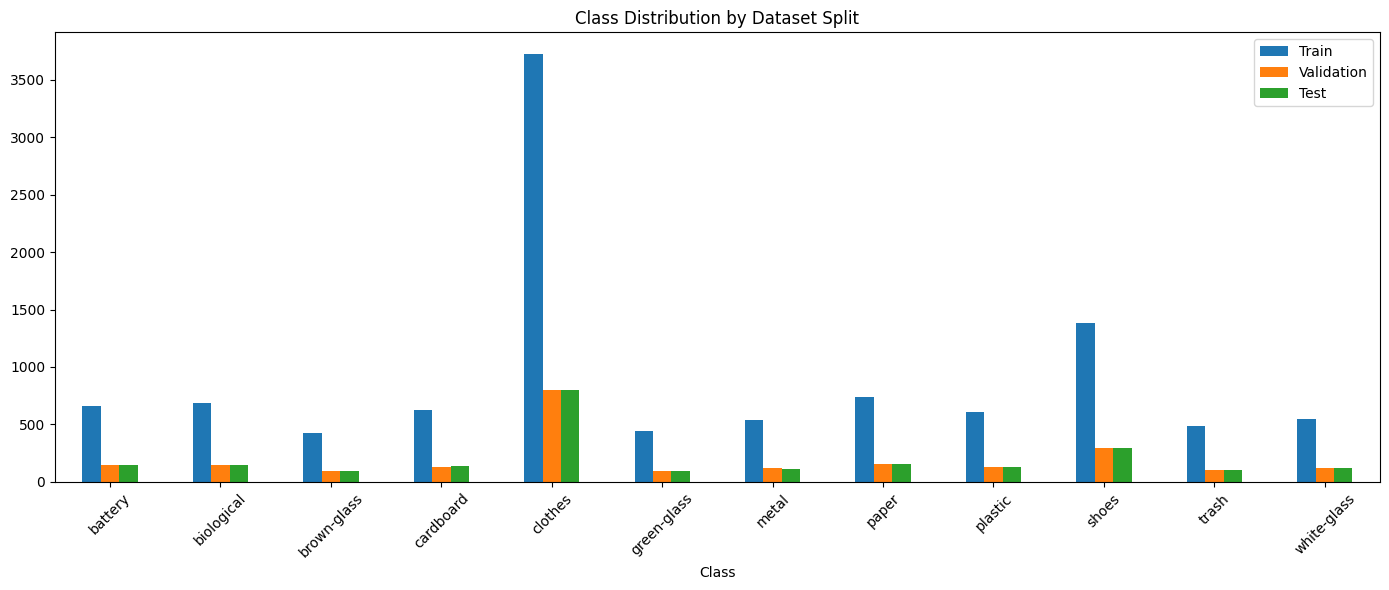


===== Batch 확인 =====
이미지 Tensor: torch.Size([32, 3, 160, 160])
정답 Label: torch.Size([32])
자료형: torch.float32
첫 번째 이미지 클래스: paper


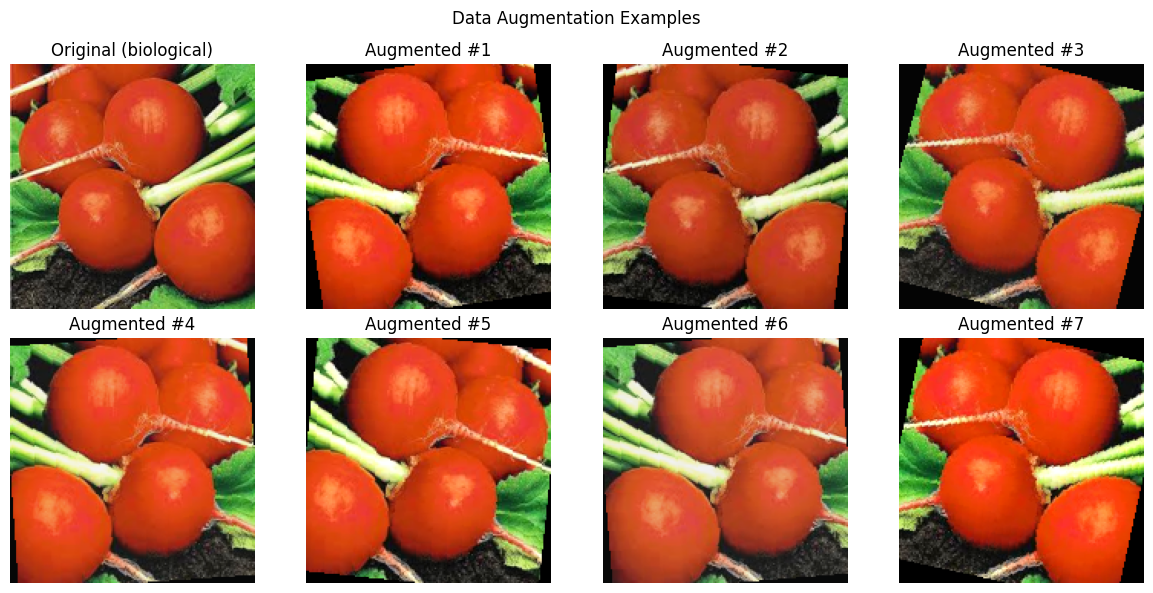


Stage 2 데이터 준비 완료


In [ ]:

# ============================================================
# Stage 2. 데이터 분석, 데이터 분할 및 전처리
# ============================================================

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. 데이터 및 클래스 확인
# ------------------------------------------------------------

assert "DATASET" in globals(), "Stage 1을 먼저 실행하세요."

classes = DATASET.classes
labels = np.array(DATASET.targets)

num_classes = len(classes)

class_counts = np.bincount(
    labels,
    minlength=num_classes
)

class_df = pd.DataFrame({
    "Class": classes,
    "Image Count": class_counts
})

print("===== 클래스별 이미지 개수 =====")
print(class_df.to_string(index=False))

print("\n전체 이미지:", len(DATASET))
print("최소 클래스 이미지:", class_counts.min())
print("최대 클래스 이미지:", class_counts.max())

# ------------------------------------------------------------
# 2. 클래스별 이미지 분포 시각화
# ------------------------------------------------------------

plt.figure(figsize=(13, 6))

sns.barplot(
    data=class_df,
    x="Class",
    y="Image Count",
    hue="Class",
    palette="viridis",
    legend=False
)

plt.title("Number of Images per Class")
plt.xlabel("Garbage Class")
plt.ylabel("Image Count")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "01_class_distribution.png"),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 3. 클래스별 샘플 이미지 확인
# ------------------------------------------------------------

fig, axes = plt.subplots(3, 4, figsize=(15, 11))
axes = axes.flatten()

for class_idx, class_name in enumerate(classes):

    class_indices = np.where(labels == class_idx)[0]

    sample_idx = random.choice(
        class_indices.tolist()
    )

    image_path, _ = DATASET.samples[sample_idx]

    img = DATASET.loader(image_path)

    axes[class_idx].imshow(img)
    axes[class_idx].set_title(class_name)
    axes[class_idx].axis("off")

plt.suptitle("Sample Images from 12 Garbage Classes")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "02_class_samples.png"),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 4. 원본 이미지 크기 확인
# ------------------------------------------------------------

sample_indices = random.sample(
    range(len(DATASET)),
    min(300, len(DATASET))
)

image_sizes = []

for idx in sample_indices:

    image_path, _ = DATASET.samples[idx]

    with Image.open(image_path) as img:
        image_sizes.append(img.size)

size_counts = Counter(image_sizes)

print("\n===== 원본 이미지 크기 상위 10개 =====")

for size, count in size_counts.most_common(10):
    print(size, ":", count)

# ------------------------------------------------------------
# 5. 층화 데이터 분할
# ------------------------------------------------------------

all_indices = np.arange(len(DATASET))

train_indices, temp_indices = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temp_indices]
)

print("\n===== 데이터 분할 결과 =====")

print("Train:", len(train_indices))
print("Validation:", len(val_indices))
print("Test:", len(test_indices))

# ------------------------------------------------------------
# 6. 클래스별 데이터 분할 분포
# ------------------------------------------------------------

split_df = pd.DataFrame({
    "Class": classes,
    "Train": np.bincount(
        labels[train_indices],
        minlength=num_classes
    ),
    "Validation": np.bincount(
        labels[val_indices],
        minlength=num_classes
    ),
    "Test": np.bincount(
        labels[test_indices],
        minlength=num_classes
    )
})

print(split_df.to_string(index=False))

split_df.set_index("Class").plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Class Distribution by Dataset Split")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "03_split_distribution.png"),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 7. 이미지 전처리 설정
# ------------------------------------------------------------

IMAGE_SIZE = 160
BATCH_SIZE = 32
NUM_WORKERS = 2

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

basic_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=MEAN,
        std=STD
    )
])

aug_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 16, IMAGE_SIZE + 16)),
    transforms.RandomCrop((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=MEAN,
        std=STD
    ),
    transforms.RandomErasing(
        p=0.15,
        scale=(0.02, 0.10)
    )
])

# ------------------------------------------------------------
# 8. 사용자 정의 Dataset
# ------------------------------------------------------------

class GarbageDataset(Dataset):

    def __init__(self, base_dataset, indices, transform=None):

        self.base_dataset = base_dataset
        self.indices = np.array(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        real_idx = int(self.indices[idx])

        image_path, label = self.base_dataset.samples[real_idx]

        image = self.base_dataset.loader(image_path)

        if self.transform is not None:
            image = self.transform(image)

        return image, label

# ------------------------------------------------------------
# 9. Train / Validation / Test Dataset 구성
# ------------------------------------------------------------

train_dataset = GarbageDataset(
    DATASET,
    train_indices,
    basic_transform
)

val_dataset = GarbageDataset(
    DATASET,
    val_indices,
    basic_transform
)

test_dataset = GarbageDataset(
    DATASET,
    test_indices,
    basic_transform
)

# ------------------------------------------------------------
# 10. DataLoader 구성
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

# ------------------------------------------------------------
# 11. Batch 확인
# ------------------------------------------------------------

images, batch_labels = next(iter(train_loader))

print("\n===== Batch 확인 =====")
print("이미지 Tensor:", images.shape)
print("정답 Label:", batch_labels.shape)
print("자료형:", images.dtype)
print("첫 번째 이미지 클래스:", classes[batch_labels[0].item()])

# ------------------------------------------------------------
# 12. 데이터 증강 시각화
# ------------------------------------------------------------

def denormalize(tensor):

    img = tensor.clone().cpu().numpy().transpose(1, 2, 0)

    img = img * np.array(STD) + np.array(MEAN)

    return np.clip(img, 0, 1)

sample_path, sample_label = DATASET.samples[
    int(train_indices[0])
]

raw_img = DATASET.loader(sample_path)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

axes[0, 0].imshow(
    raw_img.resize((IMAGE_SIZE, IMAGE_SIZE))
)

axes[0, 0].set_title(
    f"Original ({classes[sample_label]})"
)

axes[0, 0].axis("off")

for i, ax in enumerate(axes.flat[1:], start=1):

    augmented = aug_transform(raw_img)

    ax.imshow(denormalize(augmented))
    ax.set_title(f"Augmented #{i}")
    ax.axis("off")

plt.suptitle("Data Augmentation Examples")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "04_augmentation_samples.png"),
    dpi=300
)

plt.show()

print("\n" + "=" * 60)
print("Stage 2 데이터 준비 완료")
print("=" * 60)


===== 학습 환경 확인 =====
사용 장치: cuda
클래스 수: 12
학습 데이터: 10860
검증 데이터: 2327

===== Baseline CNN 구조 =====
BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, 

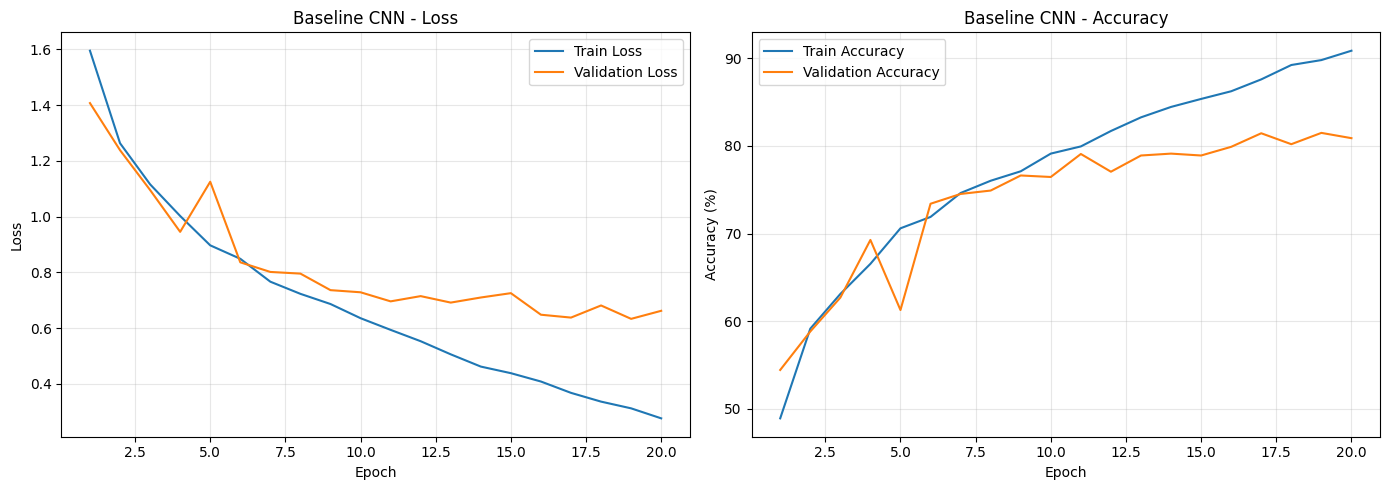


학습 그래프 저장 위치: /content/garbage_classification_results/05_baseline_training.png

===== 3단계 전체 완료 =====


In [ ]:

# =========================================================
# 3단계: 순수 Baseline CNN 모델 학습
# Conv2d + ReLU + MaxPool2d
# BatchNorm / Dropout 미사용
# =========================================================

import os
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

assert "train_loader" in globals(), "2단계를 먼저 실행하세요."
assert "val_loader" in globals(), "2단계를 먼저 실행하세요."
assert "classes" in globals(), "클래스 정보가 없습니다."

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(classes)

print("===== 학습 환경 확인 =====")
print("사용 장치:", device)
print("클래스 수:", num_classes)
print("학습 데이터:", len(train_loader.dataset))
print("검증 데이터:", len(val_loader.dataset))


# 1. Baseline CNN 모델 정의
class BaselineCNN(nn.Module):

    def __init__(self, num_classes):
        super(BaselineCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


# 2. 모델 및 학습 설정
baseline_model = BaselineCNN(num_classes).to(device)

criterion = nn.CrossEntropyLoss()

baseline_optimizer = optim.Adam(
    baseline_model.parameters(),
    lr=0.001
)

baseline_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    baseline_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5

print("\n===== Baseline CNN 구조 =====")
print(baseline_model)


# 3. 학습 및 검증 함수
def run_baseline_epoch(loader, training=True):

    if training:
        baseline_model.train()
    else:
        baseline_model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            baseline_optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            outputs = baseline_model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                baseline_optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        predictions = outputs.argmax(dim=1)

        total_correct += (predictions == labels).sum().item()
        total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy


# 4. 결과 저장 경로
if os.path.isdir("/content/drive/MyDrive"):
    RESULT_DIR = "/content/drive/MyDrive/garbage_classification_results"
else:
    RESULT_DIR = "/content/garbage_classification_results"

os.makedirs(RESULT_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    RESULT_DIR,
    "baseline_cnn_best.pth"
)

GRAPH_PATH = os.path.join(
    RESULT_DIR,
    "05_baseline_training.png"
)


# 5. 학습 결과 기록
baseline_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0
best_model_weights = None

early_stop_count = 0
start_time = time.time()


# 6. 모델 학습
print("\n===== Baseline CNN 학습 시작 =====")

for epoch in range(EPOCHS):

    train_loss, train_acc = run_baseline_epoch(
        train_loader,
        training=True
    )

    val_loss, val_acc = run_baseline_epoch(
        val_loader,
        training=False
    )

    baseline_history["train_loss"].append(train_loss)
    baseline_history["val_loss"].append(val_loss)
    baseline_history["train_acc"].append(train_acc)
    baseline_history["val_acc"].append(val_acc)

    baseline_scheduler.step(val_loss)

    current_lr = baseline_optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc * 100:.2f}% | "
        f"LR: {current_lr:.6f}"
    )

    if val_loss < best_val_loss - 0.0001:

        best_val_loss = val_loss
        best_val_acc = val_acc
        best_epoch = epoch + 1

        best_model_weights = {
            key: value.detach().cpu().clone()
            for key, value in baseline_model.state_dict().items()
        }

        torch.save(best_model_weights, MODEL_PATH)
        early_stop_count = 0

    else:
        early_stop_count += 1

    if early_stop_count >= EARLY_STOPPING_PATIENCE:

        print("\n검증 손실이 개선되지 않아 조기 종료합니다.")
        break


# 7. 최적 모델 복원
if best_model_weights is None:
    raise RuntimeError("최적 모델이 저장되지 않았습니다.")

baseline_model.load_state_dict(best_model_weights)
baseline_model.to(device)

elapsed_time = time.time() - start_time

print("\n===== Baseline CNN 학습 완료 =====")
print(f"최적 Epoch: {best_epoch}")
print(f"최적 검증 손실: {best_val_loss:.4f}")
print(f"검증 정확도: {best_val_acc * 100:.2f}%")
print(f"학습 소요 시간: {elapsed_time / 60:.2f}분")
print("모델 저장 위치:", MODEL_PATH)


# 8. 4단계 비교를 위한 변수 연결
# 기존 코드에서 history라는 이름을 사용하므로 연결
history = baseline_history


# 9. 학습 결과 그래프
epochs_range = range(
    1,
    len(baseline_history["train_loss"]) + 1
)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    baseline_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs_range,
    baseline_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN - Loss")
plt.legend()
plt.grid(alpha=0.3)


plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    [x * 100 for x in baseline_history["train_acc"]],
    label="Train Accuracy"
)

plt.plot(
    epochs_range,
    [x * 100 for x in baseline_history["val_acc"]],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Baseline CNN - Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(GRAPH_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("\n학습 그래프 저장 위치:", GRAPH_PATH)
print("\n===== 3단계 전체 완료 =====")


In [ ]:

# =========================================================
# 4-1단계: 데이터 증강, Class Weight 및 Deep CNN 모델 정의
# =========================================================

import os
import time
import random
import csv
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

assert "train_loader" in globals(), "2단계를 먼저 실행하세요."
assert "val_loader" in globals(), "2단계를 먼저 실행하세요."
assert "classes" in globals(), "클래스 정보가 없습니다."

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(classes)

IMAGE_SIZE = int(globals().get("IMAGE_SIZE", 160))
MEAN = tuple(globals().get("MEAN", (0.485, 0.456, 0.406)))
STD = tuple(globals().get("STD", (0.229, 0.224, 0.225)))


# 1. 이미지 경로 추출
def get_image_samples(loader):

    dataset = loader.dataset

    if hasattr(dataset, "base_dataset") and hasattr(dataset, "indices"):
        base_samples = dataset.base_dataset.samples
        return [base_samples[int(i)] for i in dataset.indices]

    if hasattr(dataset, "samples"):
        return list(dataset.samples)

    if hasattr(dataset, "dataset") and hasattr(dataset.dataset, "samples"):
        base_samples = dataset.dataset.samples

        if hasattr(dataset, "indices"):
            return [base_samples[int(i)] for i in dataset.indices]

    raise AttributeError("데이터셋에서 이미지 경로를 찾을 수 없습니다.")


train_samples = get_image_samples(train_loader)
val_samples = get_image_samples(val_loader)


# 2. 데이터 증강 및 검증 전처리
stage4_aug_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 16, IMAGE_SIZE + 16)),
    transforms.RandomCrop((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
    transforms.RandomErasing(
        p=0.15,
        scale=(0.02, 0.10)
    )
])

stage4_val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])


# 3. 증강 데이터셋 정의
class Stage4GarbageDataset(Dataset):

    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, int(label)


train_dataset_aug = Stage4GarbageDataset(
    train_samples,
    transform=stage4_aug_transform
)

val_dataset_stage4 = Stage4GarbageDataset(
    val_samples,
    transform=stage4_val_transform
)


# 4. DataLoader 구성
STAGE4_BATCH_SIZE = 32
NUM_WORKERS = 2

train_generator = torch.Generator()
train_generator.manual_seed(42)

train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=STAGE4_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    generator=train_generator
)

val_loader_stage4 = DataLoader(
    val_dataset_stage4,
    batch_size=STAGE4_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)


# 5. Class Weight 계산
train_labels = [
    int(label) for _, label in train_samples
]

class_counts_stage4 = torch.bincount(
    torch.tensor(train_labels, dtype=torch.long),
    minlength=num_classes
).float()

class_weights_stage4 = (
    class_counts_stage4.sum()
    / (num_classes * class_counts_stage4)
)

class_weights_stage4 = (
    class_weights_stage4 / class_weights_stage4.mean()
).to(device)


# 6. Deep CNN 모델 정의
class DeepConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super(DeepConvBlock, self).__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(kernel_size=2)
        )

    def forward(self, x):
        return self.block(x)


class ImprovedGarbageCNN(nn.Module):

    def __init__(self, num_classes):
        super(ImprovedGarbageCNN, self).__init__()

        self.features = nn.Sequential(
            DeepConvBlock(3, 32),
            DeepConvBlock(32, 64),
            DeepConvBlock(64, 128),
            DeepConvBlock(128, 256),
            DeepConvBlock(256, 512)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(
                    m.weight,
                    mode="fan_out",
                    nonlinearity="relu"
                )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


print("===== 4-1단계 준비 완료 =====")
print("증강 학습 데이터:", len(train_dataset_aug))
print("검증 데이터:", len(val_dataset_stage4))
print("클래스 가중치:", class_weights_stage4)
print("개선 CNN 모델 정의 완료")


===== 4-1단계 준비 완료 =====
증강 학습 데이터: 10860
검증 데이터: 2327
클래스 가중치: tensor([0.9583, 0.9194, 1.4905, 1.0152, 0.1700, 1.4397, 1.1774, 0.8619, 1.0453,
        0.4577, 1.2981, 1.1666], device='cuda:0')
개선 CNN 모델 정의 완료



실험 시작: ReduceLROnPlateau
Epoch [01/25] Train Loss: 1.9190 | Train Acc: 39.27% | Val Loss: 2.3872 | Val Acc: 31.54% | LR: 0.001000
Epoch [02/25] Train Loss: 1.7333 | Train Acc: 46.94% | Val Loss: 1.5823 | Val Acc: 52.86% | LR: 0.001000
Epoch [03/25] Train Loss: 1.6321 | Train Acc: 51.06% | Val Loss: 1.7099 | Val Acc: 50.45% | LR: 0.001000
Epoch [04/25] Train Loss: 1.5882 | Train Acc: 53.46% | Val Loss: 1.4222 | Val Acc: 61.19% | LR: 0.001000
Epoch [05/25] Train Loss: 1.5338 | Train Acc: 56.69% | Val Loss: 1.4334 | Val Acc: 56.47% | LR: 0.001000
Epoch [06/25] Train Loss: 1.4840 | Train Acc: 58.44% | Val Loss: 1.3827 | Val Acc: 59.86% | LR: 0.001000
Epoch [07/25] Train Loss: 1.4383 | Train Acc: 60.34% | Val Loss: 1.3374 | Val Acc: 63.47% | LR: 0.001000
Epoch [08/25] Train Loss: 1.4071 | Train Acc: 61.38% | Val Loss: 1.7673 | Val Acc: 54.71% | LR: 0.001000
Epoch [09/25] Train Loss: 1.3670 | Train Acc: 63.51% | Val Loss: 1.2451 | Val Acc: 70.48% | LR: 0.001000
Epoch [10/25] Train Loss: 1.3

/tmp/ipykernel_795/2715804384.py:412: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_795/2715804384.py:412: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_795/2715804384.py:419: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.savefig(
/tmp/ipykernel_795/2715804384.py:419: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.savefig(
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


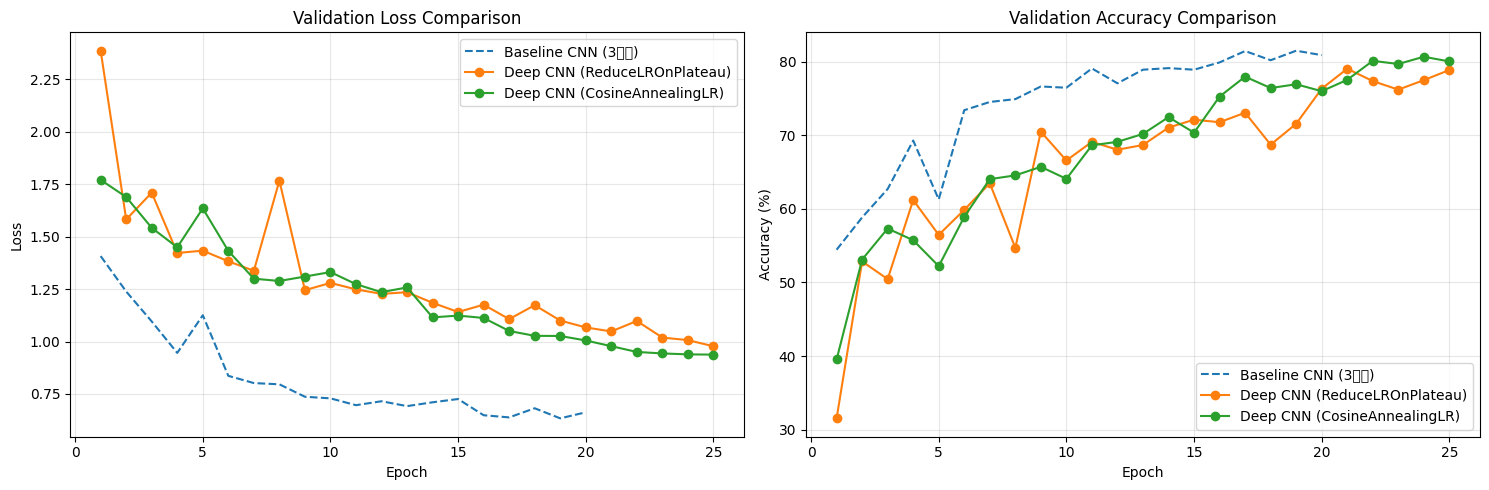


비교표 저장: /content/garbage_classification_results/stage4_experiment_comparison.csv
비교 그래프 저장: /content/garbage_classification_results/06_stage4_scheduler_comparison.png

===== 4단계 완료 =====


In [ ]:

# =========================================================
# 4-2단계: 스케줄러 비교 실험 및 결과 그래프 저장
# =========================================================

def set_stage4_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


MAX_EPOCHS = 25
EARLY_STOPPING_PATIENCE = 6
MIN_EPOCHS_COSINE = 18
LEARNING_RATE = 0.001

EXPERIMENTS = [
    "ReduceLROnPlateau",
    "CosineAnnealingLR"
]


# 결과 저장 경로
if os.path.isdir("/content/drive/MyDrive"):
    RESULT_DIR = "/content/drive/MyDrive/garbage_classification_results"
else:
    RESULT_DIR = "/content/garbage_classification_results"

os.makedirs(RESULT_DIR, exist_ok=True)


# 1. 스케줄러별 학습 함수
def train_stage4_experiment(scheduler_name, seed=42):

    set_stage4_seed(seed)

    model = ImprovedGarbageCNN(num_classes).to(device)

    criterion_stage4 = nn.CrossEntropyLoss(
        weight=class_weights_stage4,
        label_smoothing=0.05
    )

    optimizer_stage4 = optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=0.0001
    )

    if scheduler_name == "ReduceLROnPlateau":

        scheduler_stage4 = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer_stage4,
            mode="min",
            factor=0.5,
            patience=2,
            min_lr=1e-5
        )

    else:

        scheduler_stage4 = optim.lr_scheduler.CosineAnnealingLR(
            optimizer_stage4,
            T_max=MAX_EPOCHS,
            eta_min=1e-5
        )


    history_exp = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_val_acc = 0.0
    best_epoch = 0
    best_weights = None
    early_stop_count = 0

    experiment_start = time.time()

    print("\n" + "=" * 60)
    print("실험 시작:", scheduler_name)
    print("=" * 60)


    # 2. 학습 반복
    for epoch in range(MAX_EPOCHS):

        model.train()

        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader_aug:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer_stage4.zero_grad(set_to_none=True)

            outputs = model(images)
            loss = criterion_stage4(outputs, labels)

            loss.backward()
            optimizer_stage4.step()

            batch_size = labels.size(0)

            train_loss_sum += loss.item() * batch_size
            train_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

            train_total += batch_size

        train_loss = train_loss_sum / train_total
        train_acc = train_correct / train_total


        # 3. 검증
        model.eval()

        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader_stage4:

                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                outputs = model(images)
                loss = criterion_stage4(outputs, labels)

                batch_size = labels.size(0)

                val_loss_sum += loss.item() * batch_size

                val_correct += (
                    outputs.argmax(dim=1) == labels
                ).sum().item()

                val_total += batch_size

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total


        history_exp["train_loss"].append(train_loss)
        history_exp["val_loss"].append(val_loss)
        history_exp["train_acc"].append(train_acc)
        history_exp["val_acc"].append(val_acc)


        # 4. 스케줄러 업데이트
        if scheduler_name == "ReduceLROnPlateau":
            scheduler_stage4.step(val_loss)
        else:
            scheduler_stage4.step()

        current_lr = optimizer_stage4.param_groups[0]["lr"]

        print(
            f"Epoch [{epoch + 1:02d}/{MAX_EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc * 100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc * 100:.2f}% | "
            f"LR: {current_lr:.6f}"
        )


        # 5. 최적 모델 저장
        if val_loss < best_val_loss - 0.0001:

            best_val_loss = val_loss
            best_val_acc = val_acc
            best_epoch = epoch + 1

            best_weights = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            early_stop_count = 0

        else:
            early_stop_count += 1


        # CosineAnnealingLR은 최소 학습 epoch 보장
        can_stop = (
            scheduler_name != "CosineAnnealingLR"
            or epoch + 1 >= MIN_EPOCHS_COSINE
        )

        if (
            can_stop
            and early_stop_count >= EARLY_STOPPING_PATIENCE
        ):
            print("검증 손실 개선이 없어 조기 종료합니다.")
            break


    elapsed_time = time.time() - experiment_start

    if best_weights is None:
        raise RuntimeError(
            f"{scheduler_name} 실험에서 최적 가중치를 저장하지 못했습니다."
        )

    experiment_path = os.path.join(
        RESULT_DIR,
        f"improved_cnn_{scheduler_name}.pth"
    )

    torch.save(best_weights, experiment_path)

    print(
        f"\n실험 완료: {scheduler_name} | "
        f"최적 Epoch: {best_epoch} | "
        f"검증 손실: {best_val_loss:.4f} | "
        f"검증 정확도: {best_val_acc * 100:.2f}% | "
        f"소요: {elapsed_time / 60:.2f}분"
    )

    result = {
        "scheduler": scheduler_name,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_acc": best_val_acc,
        "elapsed_time": elapsed_time,
        "history": history_exp,
        "state_dict": best_weights,
        "model_path": experiment_path
    }

    del model, optimizer_stage4, criterion_stage4

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# 6. 스케줄러별 실험 실행
stage4_results = []

for experiment_name in EXPERIMENTS:

    result = train_stage4_experiment(
        scheduler_name=experiment_name,
        seed=42
    )

    stage4_results.append(result)


# 7. 최적 모델 선정
best_stage4_result = min(
    stage4_results,
    key=lambda x: x["best_val_loss"]
)

improved_model = ImprovedGarbageCNN(num_classes).to(device)

improved_model.load_state_dict(
    best_stage4_result["state_dict"]
)

improved_model.eval()

FINAL_MODEL_PATH = os.path.join(
    RESULT_DIR,
    "stage4_best_improved_cnn.pth"
)

torch.save(
    best_stage4_result["state_dict"],
    FINAL_MODEL_PATH
)

print("\n===== 최종 개선 모델 선정 =====")
print("선정된 스케줄러:", best_stage4_result["scheduler"])
print("최적 Epoch:", best_stage4_result["best_epoch"])
print(f"최적 검증 손실: {best_stage4_result['best_val_loss']:.4f}")
print(f"검증 정확도: {best_stage4_result['best_val_acc'] * 100:.2f}%")


# 8. Baseline 및 스케줄러 비교표
comparison_rows = []

baseline_min_idx = int(np.argmin(history["val_loss"]))

comparison_rows.append({
    "Model / Scheduler": "Baseline CNN (3단계)",
    "Best Epoch": baseline_min_idx + 1,
    "Validation Loss": round(history["val_loss"][baseline_min_idx], 4),
    "Validation Accuracy (%)": round(
        history["val_acc"][baseline_min_idx] * 100, 2
    ),
    "Overfit Gap (%p)": round(
        (history["train_acc"][-1] - history["val_acc"][-1]) * 100, 2
    ),
    "Training Time (min)": round(elapsed_time / 60, 2)
})

for result in stage4_results:

    h = result["history"]

    comparison_rows.append({
        "Model / Scheduler": f"Deep CNN ({result['scheduler']})",
        "Best Epoch": result["best_epoch"],
        "Validation Loss": round(result["best_val_loss"], 4),
        "Validation Accuracy (%)": round(
            result["best_val_acc"] * 100, 2
        ),
        "Overfit Gap (%p)": round(
            (h["train_acc"][-1] - h["val_acc"][-1]) * 100, 2
        ),
        "Training Time (min)": round(
            result["elapsed_time"] / 60, 2
        )
    })


print("\n===== 전체 모델 및 스케줄러 비교표 =====")

for row in comparison_rows:
    print(row)


# CSV 저장
CSV_PATH = os.path.join(
    RESULT_DIR,
    "stage4_experiment_comparison.csv"
)

with open(CSV_PATH, "w", newline="", encoding="utf-8-sig") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=comparison_rows[0].keys()
    )

    writer.writeheader()
    writer.writerows(comparison_rows)


# 9. 비교 그래프
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

b_ep = range(1, len(history["val_loss"]) + 1)

axes[0].plot(
    b_ep,
    history["val_loss"],
    linestyle="--",
    label="Baseline CNN (3단계)"
)

axes[1].plot(
    b_ep,
    [x * 100 for x in history["val_acc"]],
    linestyle="--",
    label="Baseline CNN (3단계)"
)


for result in stage4_results:

    hist = result["history"]
    ep = range(1, len(hist["val_loss"]) + 1)

    axes[0].plot(
        ep,
        hist["val_loss"],
        marker="o",
        label=f"Deep CNN ({result['scheduler']})"
    )

    axes[1].plot(
        ep,
        [x * 100 for x in hist["val_acc"]],
        marker="o",
        label=f"Deep CNN ({result['scheduler']})"
    )


axes[0].set_title("Validation Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Validation Accuracy Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

GRAPH_PATH = os.path.join(
    RESULT_DIR,
    "06_stage4_scheduler_comparison.png"
)

plt.savefig(
    GRAPH_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\n비교표 저장:", CSV_PATH)
print("비교 그래프 저장:", GRAPH_PATH)
print("\n===== 4단계 완료 =====")


사용 장치: cuda
클래스 수: 12

학습률 0.0005 실험 시작
Epoch [01/25] Train Loss: 1.8391 | Train Acc: 42.73% | Val Loss: 1.7374 | Val Acc: 47.74%
Epoch [02/25] Train Loss: 1.6412 | Train Acc: 50.33% | Val Loss: 1.5960 | Val Acc: 47.83%
Epoch [03/25] Train Loss: 1.5344 | Train Acc: 55.41% | Val Loss: 1.5565 | Val Acc: 49.72%
Epoch [04/25] Train Loss: 1.4824 | Train Acc: 57.45% | Val Loss: 1.4811 | Val Acc: 53.46%
Epoch [05/25] Train Loss: 1.3997 | Train Acc: 61.27% | Val Loss: 1.3326 | Val Acc: 68.50%
Epoch [06/25] Train Loss: 1.3738 | Train Acc: 62.39% | Val Loss: 1.2565 | Val Acc: 67.77%
Epoch [07/25] Train Loss: 1.3152 | Train Acc: 65.02% | Val Loss: 1.2523 | Val Acc: 65.28%
Epoch [08/25] Train Loss: 1.2703 | Train Acc: 66.57% | Val Loss: 1.2048 | Val Acc: 69.62%
Epoch [09/25] Train Loss: 1.2314 | Train Acc: 67.42% | Val Loss: 1.1494 | Val Acc: 68.46%
Epoch [10/25] Train Loss: 1.1939 | Train Acc: 69.55% | Val Loss: 1.1689 | Val Acc: 73.10%
Epoch [11/25] Train Loss: 1.1462 | Train Acc: 71.32% | Val L

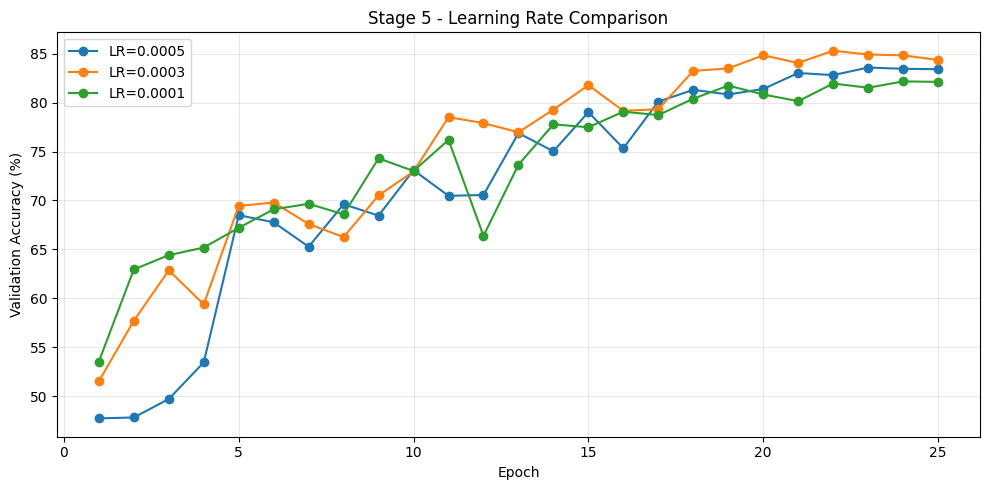

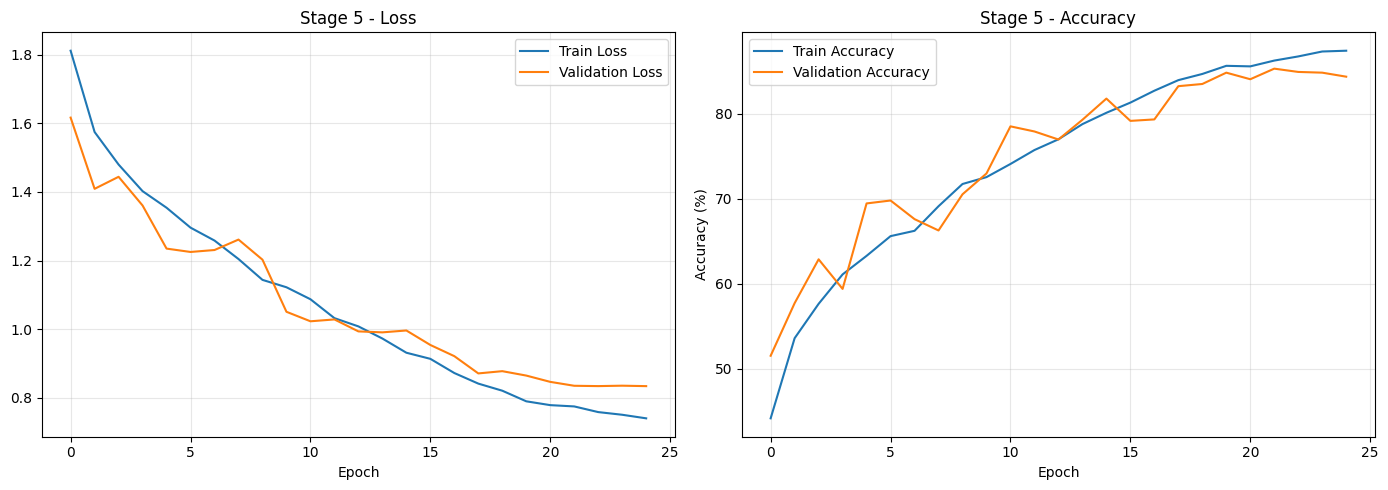


===== 5단계 완료 =====


In [ ]:

# =========================================================
# 5단계: Learning Rate 비교 및 최적 모델 선정
# =========================================================

import os
import time
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader


# 1. 실행 환경 확인
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert "ImprovedGarbageCNN" in globals(), "4-1단계 모델 정의를 먼저 실행하세요."
assert "train_loader_aug" in globals(), "4-1단계 데이터 증강을 먼저 실행하세요."
assert "val_loader_stage4" in globals(), "4-1단계 검증 데이터가 필요합니다."

num_classes = len(classes)

print("사용 장치:", device)
print("클래스 수:", num_classes)


# 2. 실험 설정
LEARNING_RATES = [0.0005, 0.0003, 0.0001]

EPOCHS_STAGE5 = 25
PATIENCE_STAGE5 = 6

stage5_results = []


# 3. 재현성을 위한 시드 설정
def set_stage5_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# 4. 학습률별 실험 함수
def train_stage5_experiment(lr, seed=42):

    set_stage5_seed(seed)

    model = ImprovedGarbageCNN(num_classes).to(device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights_stage4,
        label_smoothing=0.05
    )

    optimizer = optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=0.0001
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS_STAGE5,
        eta_min=1e-6
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_val_acc = 0.0
    best_epoch = 0
    best_weights = None
    early_stop_count = 0

    start_time = time.time()

    print("\n" + "=" * 60)
    print(f"학습률 {lr} 실험 시작")
    print("=" * 60)


    # 5. 반복 학습
    for epoch in range(EPOCHS_STAGE5):

        model.train()

        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader_aug:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=2.0
            )

            optimizer.step()

            batch_size = labels.size(0)

            train_loss_sum += loss.item() * batch_size
            train_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

            train_total += batch_size

        train_loss = train_loss_sum / train_total
        train_acc = train_correct / train_total


        # 6. 검증
        model.eval()

        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader_stage4:

                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                outputs = model(images)
                loss = criterion(outputs, labels)

                batch_size = labels.size(0)

                val_loss_sum += loss.item() * batch_size

                val_correct += (
                    outputs.argmax(dim=1) == labels
                ).sum().item()

                val_total += batch_size

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch [{epoch + 1:02d}/{EPOCHS_STAGE5}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc * 100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc * 100:.2f}%"
        )


        # 7. 최적 가중치 저장
        if val_loss < best_val_loss - 0.0001:

            best_val_loss = val_loss
            best_val_acc = val_acc
            best_epoch = epoch + 1

            best_weights = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            early_stop_count = 0

        else:
            early_stop_count += 1

        if early_stop_count >= PATIENCE_STAGE5:
            print("조기 종료합니다.")
            break


    elapsed_time = time.time() - start_time

    if best_weights is None:
        raise RuntimeError(f"학습률 {lr}의 모델 저장에 실패했습니다.")

    result = {
        "lr": lr,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_acc": best_val_acc,
        "elapsed_time": elapsed_time,
        "history": history,
        "state_dict": best_weights
    }

    print(f"\n학습률 {lr} 실험 완료")
    print(f"최적 Epoch: {best_epoch}")
    print(f"최적 검증 손실: {best_val_loss:.4f}")
    print(f"검증 정확도: {best_val_acc * 100:.2f}%")
    print(f"소요 시간: {elapsed_time / 60:.2f}분")

    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# 8. 학습률별 실험 실행
for lr in LEARNING_RATES:

    result = train_stage5_experiment(lr)

    stage5_results.append(result)


# 9. 검증 손실이 가장 낮은 모델 선정
best_stage5_result = min(
    stage5_results,
    key=lambda x: x["best_val_loss"]
)

best_lr = best_stage5_result["lr"]

best_model_stage5 = ImprovedGarbageCNN(num_classes).to(device)

best_model_stage5.load_state_dict(
    best_stage5_result["state_dict"]
)

best_model_stage5.eval()


# 10. 최적 모델 저장
if os.path.isdir("/content/drive/MyDrive"):
    RESULT_DIR = "/content/drive/MyDrive/garbage_classification_results"
else:
    RESULT_DIR = "/content/garbage_classification_results"

os.makedirs(RESULT_DIR, exist_ok=True)

STAGE5_MODEL_PATH = os.path.join(
    RESULT_DIR,
    "final_tuned_garbage_cnn.pth"
)

torch.save(
    best_stage5_result["state_dict"],
    STAGE5_MODEL_PATH
)


# 11. 학습률 비교 결과 출력
print("\n" + "=" * 70)
print("5단계 학습률 비교 결과")
print("=" * 70)

for result in stage5_results:

    print(
        f"LR: {result['lr']:.5f} | "
        f"Best Epoch: {result['best_epoch']} | "
        f"Val Loss: {result['best_val_loss']:.4f} | "
        f"Val Accuracy: {result['best_val_acc'] * 100:.2f}% | "
        f"Time: {result['elapsed_time'] / 60:.2f}분"
    )

print("\n===== 최종 선정 모델 =====")
print("선정 학습률:", best_lr)
print("최적 Epoch:", best_stage5_result["best_epoch"])
print(f"검증 손실: {best_stage5_result['best_val_loss']:.4f}")
print(f"검증 정확도: {best_stage5_result['best_val_acc'] * 100:.2f}%")
print("저장 경로:", STAGE5_MODEL_PATH)


# 12. 학습률별 검증 정확도 비교 그래프
plt.figure(figsize=(10, 5))

for result in stage5_results:

    epochs = range(
        1,
        len(result["history"]["val_acc"]) + 1
    )

    plt.plot(
        epochs,
        [x * 100 for x in result["history"]["val_acc"]],
        marker="o",
        label=f"LR={result['lr']}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Stage 5 - Learning Rate Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "07_stage5_lr_comparison.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# 13. 최적 모델 학습 곡선
best_history = best_stage5_result["history"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(best_history["train_loss"], label="Train Loss")
axes[0].plot(best_history["val_loss"], label="Validation Loss")
axes[0].set_title("Stage 5 - Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    np.array(best_history["train_acc"]) * 100,
    label="Train Accuracy"
)

axes[1].plot(
    np.array(best_history["val_acc"]) * 100,
    label="Validation Accuracy"
)

axes[1].set_title("Stage 5 - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "08_stage5_best_training.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\n===== 5단계 완료 =====")


Stage 5 최적 모델 테스트 평가
Accuracy          : 85.9536%
Balanced Accuracy : 86.1776%
Macro Precision   : 82.5843%
Macro Recall      : 86.1776%
Macro F1-score    : 84.1724%
Weighted F1-score : 86.0836%

===== 클래스별 평가 결과 =====
              precision    recall  f1-score   support

     battery     0.8516    0.7676    0.8074       142
  biological     0.7870    0.8986    0.8391       148
 brown-glass     0.8384    0.9121    0.8737        91
   cardboard     0.8623    0.8881    0.8750       134
     clothes     0.9748    0.8698    0.9193       799
 green-glass     0.8378    0.9894    0.9073        94
       metal     0.7372    0.8783    0.8016       115
       paper     0.8303    0.8671    0.8483       158
     plastic     0.8000    0.7692    0.7843       130
       shoes     0.7898    0.8350    0.8118       297
       trash     0.8241    0.8558    0.8396       104
 white-glass     0.7769    0.8103    0.7932       116

    accuracy                         0.8595      2328
   macro avg     0.8258

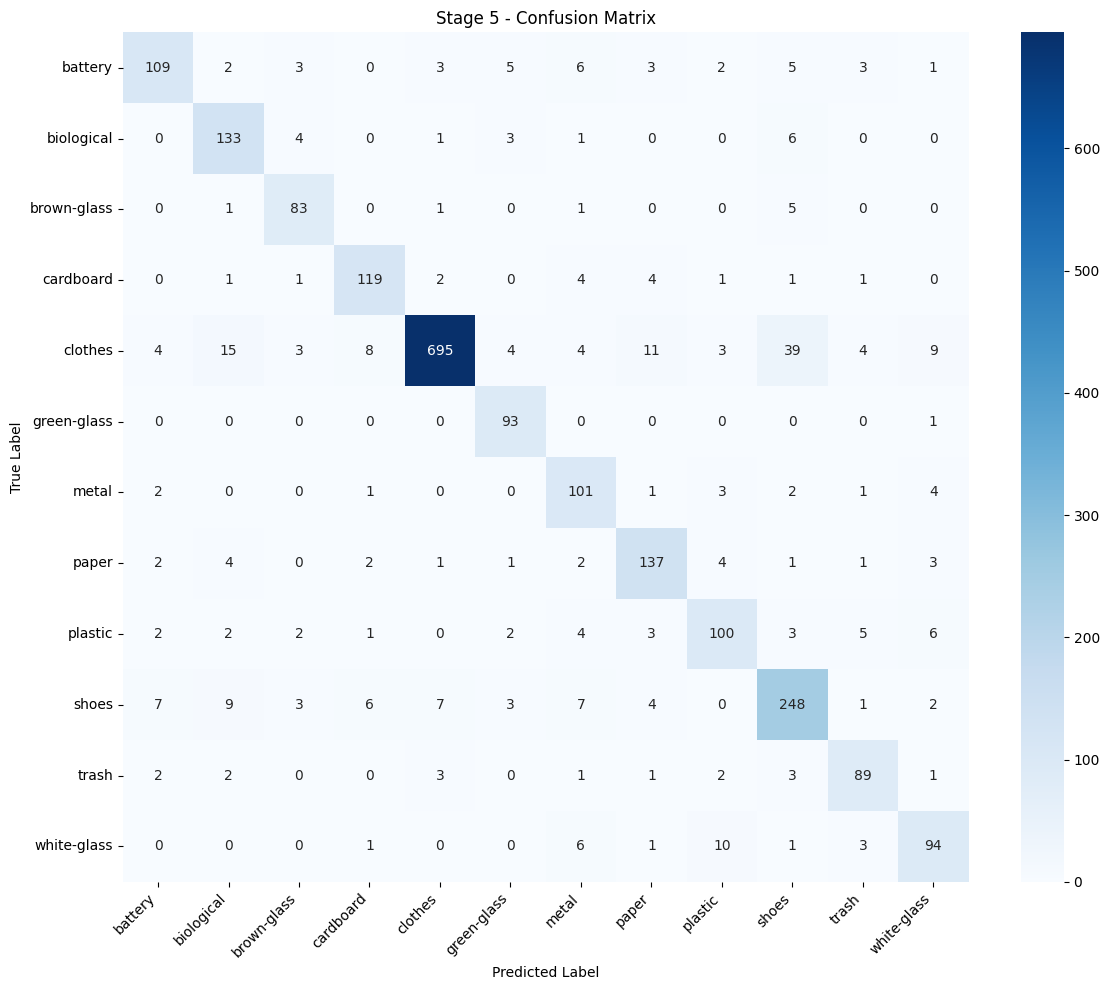

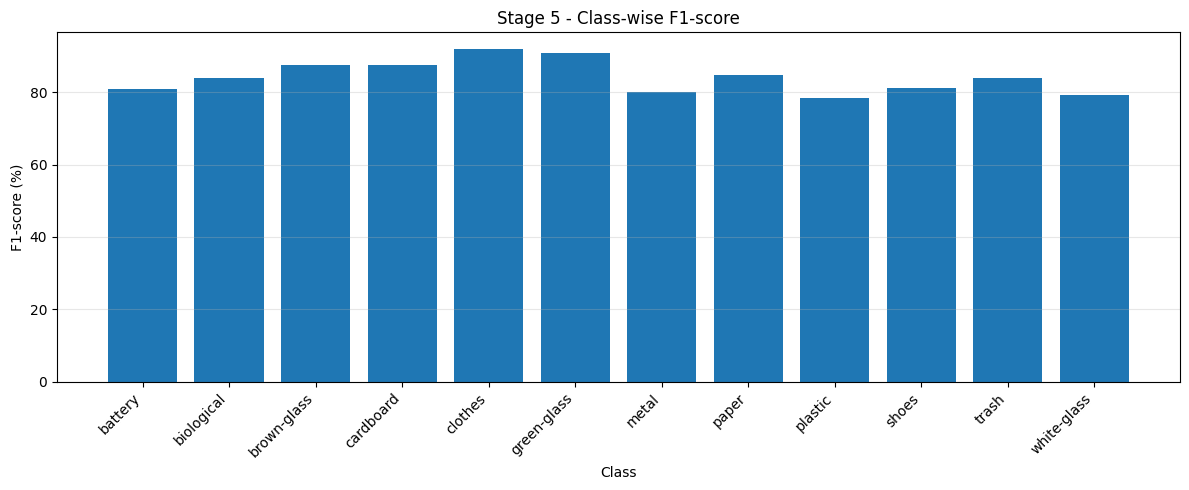


===== 6단계 완료 =====


In [ ]:

# =========================================================
# 6단계: Stage 5 최적 모델 테스트 데이터 평가
# =========================================================

import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

assert "test_loader" in globals(), "2단계의 test_loader가 필요합니다."
assert "best_model_stage5" in globals(), "5단계를 먼저 실행하세요."

best_model_stage5.eval()

all_labels_stage5 = []
all_preds_stage5 = []
all_probs_stage5 = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        outputs = best_model_stage5(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = probabilities.argmax(dim=1)

        all_labels_stage5.extend(labels.cpu().numpy())
        all_preds_stage5.extend(predictions.cpu().numpy())
        all_probs_stage5.extend(probabilities.cpu().numpy())


y_true_stage5 = np.array(all_labels_stage5)
y_pred_stage5 = np.array(all_preds_stage5)
y_prob_stage5 = np.array(all_probs_stage5)


# 1. 평가 지표 계산
stage5_accuracy = accuracy_score(
    y_true_stage5, y_pred_stage5
)

stage5_balanced_accuracy = balanced_accuracy_score(
    y_true_stage5, y_pred_stage5
)

stage5_precision = precision_score(
    y_true_stage5,
    y_pred_stage5,
    average="macro",
    zero_division=0
)

stage5_recall = recall_score(
    y_true_stage5,
    y_pred_stage5,
    average="macro",
    zero_division=0
)

stage5_macro_f1 = f1_score(
    y_true_stage5,
    y_pred_stage5,
    average="macro",
    zero_division=0
)

stage5_weighted_f1 = f1_score(
    y_true_stage5,
    y_pred_stage5,
    average="weighted",
    zero_division=0
)


# 2. 전체 평가 결과
print("=" * 65)
print("Stage 5 최적 모델 테스트 평가")
print("=" * 65)

print(f"Accuracy          : {stage5_accuracy * 100:.4f}%")
print(f"Balanced Accuracy : {stage5_balanced_accuracy * 100:.4f}%")
print(f"Macro Precision   : {stage5_precision * 100:.4f}%")
print(f"Macro Recall      : {stage5_recall * 100:.4f}%")
print(f"Macro F1-score    : {stage5_macro_f1 * 100:.4f}%")
print(f"Weighted F1-score : {stage5_weighted_f1 * 100:.4f}%")


# 3. 클래스별 평가 결과
print("\n===== 클래스별 평가 결과 =====")

print(
    classification_report(
        y_true_stage5,
        y_pred_stage5,
        target_names=classes,
        digits=4,
        zero_division=0
    )
)


# 4. 혼동행렬
cm_stage5 = confusion_matrix(
    y_true_stage5,
    y_pred_stage5,
    labels=list(range(num_classes))
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_stage5,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Stage 5 - Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "09_stage5_confusion_matrix.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# 5. 클래스별 F1-score 그래프
class_report_stage5 = classification_report(
    y_true_stage5,
    y_pred_stage5,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

class_f1_stage5 = [
    class_report_stage5[name]["f1-score"]
    for name in classes
]

plt.figure(figsize=(12, 5))

plt.bar(classes, np.array(class_f1_stage5) * 100)

plt.xlabel("Class")
plt.ylabel("F1-score (%)")
plt.title("Stage 5 - Class-wise F1-score")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "10_stage5_class_f1.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# 6. 결과 저장
stage5_test_results = {
    "accuracy": stage5_accuracy,
    "balanced_accuracy": stage5_balanced_accuracy,
    "macro_precision": stage5_precision,
    "macro_recall": stage5_recall,
    "macro_f1": stage5_macro_f1,
    "weighted_f1": stage5_weighted_f1
}

np.savez(
    os.path.join(RESULT_DIR, "stage5_test_predictions.npz"),
    y_true=y_true_stage5,
    y_pred=y_pred_stage5,
    y_prob=y_prob_stage5
)

print("\n===== 6단계 완료 =====")


Stage 7 - TTA 성능 비교
평가지표                               기본 모델         TTA 모델
-------------------------------------------------------
Accuracy                        85.9536%       86.2543%
변화                              +0.3007%p
Macro F1                        84.1724%       84.3326%
변화                              +0.1602%p
Weighted F1                     86.0836%       86.3877%
변화                              +0.3041%p

기본 예측 오류를 수정한 수: 30
TTA 적용 후 새롭게 발생한 오류: 23


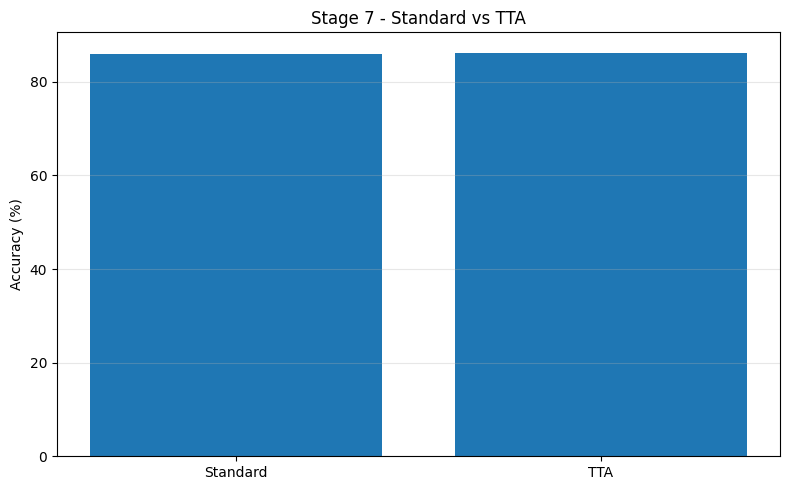


===== 7단계 완료 =====


In [ ]:

# =========================================================
# 7단계: Test Time Augmentation (TTA)
# =========================================================

import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


best_model_stage5.eval()

tta_labels = []
tta_preds = []
tta_probs = []

standard_labels = []
standard_preds = []


# 1. 원본 이미지와 좌우 반전 이미지 예측
with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        # 원본 이미지 예측
        outputs_original = best_model_stage5(images)

        probs_original = torch.softmax(
            outputs_original,
            dim=1
        )

        # 좌우 반전 이미지 예측
        flipped_images = torch.flip(
            images,
            dims=[3]
        )

        outputs_flipped = best_model_stage5(flipped_images)

        probs_flipped = torch.softmax(
            outputs_flipped,
            dim=1
        )

        # 두 예측 확률 평균
        tta_probabilities = (
            probs_original + probs_flipped
        ) / 2

        tta_predictions = tta_probabilities.argmax(dim=1)

        standard_predictions = probs_original.argmax(dim=1)

        labels_np = labels.cpu().numpy()

        tta_labels.extend(labels_np)
        tta_preds.extend(tta_predictions.cpu().numpy())
        tta_probs.extend(tta_probabilities.cpu().numpy())

        standard_labels.extend(labels_np)
        standard_preds.extend(standard_predictions.cpu().numpy())


# 2. 결과 배열 변환
tta_labels = np.array(tta_labels)
tta_preds = np.array(tta_preds)
tta_probs = np.array(tta_probs)

standard_labels = np.array(standard_labels)
standard_preds = np.array(standard_preds)


# 3. 성능 계산
standard_accuracy = accuracy_score(
    standard_labels,
    standard_preds
)

tta_accuracy = accuracy_score(
    tta_labels,
    tta_preds
)

standard_macro_f1 = f1_score(
    standard_labels,
    standard_preds,
    average="macro",
    zero_division=0
)

tta_macro_f1 = f1_score(
    tta_labels,
    tta_preds,
    average="macro",
    zero_division=0
)

standard_weighted_f1 = f1_score(
    standard_labels,
    standard_preds,
    average="weighted",
    zero_division=0
)

tta_weighted_f1 = f1_score(
    tta_labels,
    tta_preds,
    average="weighted",
    zero_division=0
)


# 4. 결과 비교
print("=" * 65)
print("Stage 7 - TTA 성능 비교")
print("=" * 65)

print(
    f"{'평가지표':<25}"
    f"{'기본 모델':>15}"
    f"{'TTA 모델':>15}"
)

print("-" * 55)

metrics = [
    ("Accuracy", standard_accuracy, tta_accuracy),
    ("Macro F1", standard_macro_f1, tta_macro_f1),
    ("Weighted F1", standard_weighted_f1, tta_weighted_f1)
]

for name, standard, tta in metrics:

    print(
        f"{name:<25}"
        f"{standard * 100:>14.4f}%"
        f"{tta * 100:>14.4f}%"
    )

    print(
        f"{'변화':<25}"
        f"{(tta - standard) * 100:>+14.4f}%p"
    )


# 5. 예측 변화 확인
corrected = np.sum(
    (standard_preds != standard_labels)
    & (tta_preds == tta_labels)
)

introduced = np.sum(
    (standard_preds == standard_labels)
    & (tta_preds != tta_labels)
)

print("\n기본 예측 오류를 수정한 수:", corrected)
print("TTA 적용 후 새롭게 발생한 오류:", introduced)


# 6. 결과 저장
np.savez(
    os.path.join(RESULT_DIR, "stage7_tta_predictions.npz"),
    y_true=tta_labels,
    y_pred=tta_preds,
    y_prob=tta_probs,
    standard_pred=standard_preds
)


# 7. 정확도 비교 그래프
plt.figure(figsize=(8, 5))

plt.bar(
    ["Standard", "TTA"],
    [standard_accuracy * 100, tta_accuracy * 100]
)

plt.ylabel("Accuracy (%)")
plt.title("Stage 7 - Standard vs TTA")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "11_stage7_tta_comparison.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\n===== 7단계 완료 =====")


===== 클래스별 학습 데이터 수 =====
battery        : 661
biological     : 689
brown-glass    : 425
cardboard      : 624
clothes        : 3727
green-glass    : 440
metal          : 538
paper          : 735
plastic        : 606
shoes          : 1384
trash          : 488
white-glass    : 543

Weighted Sampling DataLoader 생성 완료
학습 데이터 수: 10860

===== Stage 8 Weighted Sampling 학습 시작 =====
Epoch [01/12] Train Loss: 1.7334 | Train Acc: 44.21% | Val Loss: 1.3590 | Val Acc: 58.87% | LR: 0.0000492
Epoch [02/12] Train Loss: 1.3821 | Train Acc: 55.27% | Val Loss: 1.1510 | Val Acc: 63.26% | LR: 0.0000467
Epoch [03/12] Train Loss: 1.2389 | Train Acc: 60.66% | Val Loss: 1.0288 | Val Acc: 66.61% | LR: 0.0000428
Epoch [04/12] Train Loss: 1.1820 | Train Acc: 61.86% | Val Loss: 0.9435 | Val Acc: 70.18% | LR: 0.0000378
Epoch [05/12] Train Loss: 1.1152 | Train Acc: 64.26% | Val Loss: 0.9648 | Val Acc: 68.67% | LR: 0.0000318
Epoch [06/12] Train Loss: 1.0527 | Train Acc: 65.94% | Val Loss: 0.9768 | Val Acc: 68.59% | L

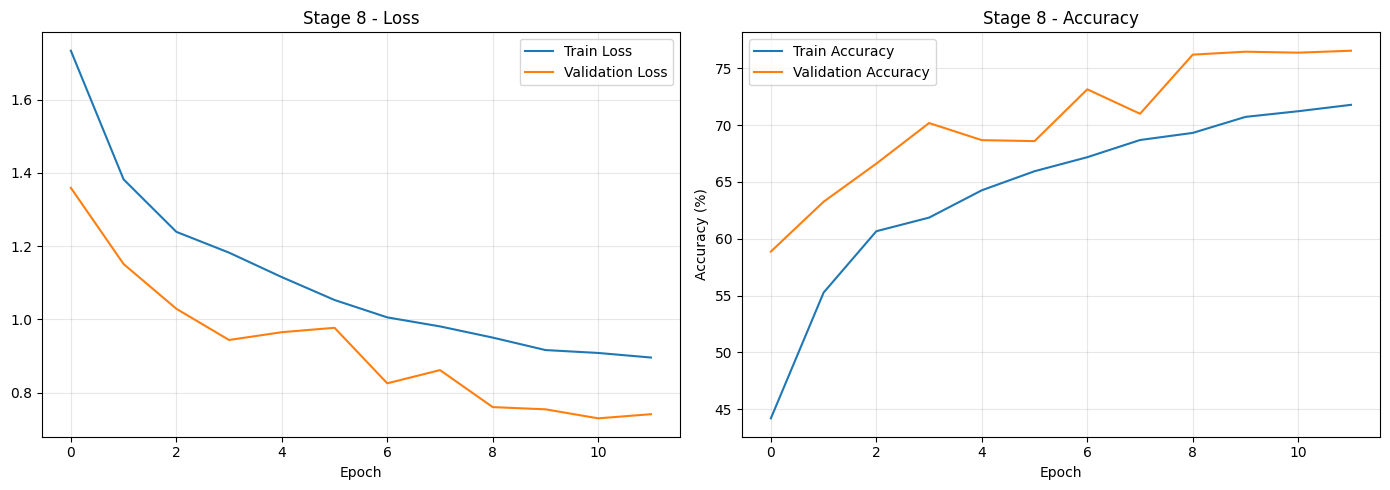


===== 8단계 완료 =====


In [ ]:

# =========================================================
# 8단계: Weighted Sampling 기반 모델 학습
# =========================================================

import os
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, WeightedRandomSampler


assert "train_samples" in globals(), "4-1단계를 먼저 실행하세요."
assert "val_loader_stage4" in globals(), "4-1단계 검증 데이터가 필요합니다."


# 1. 재현성 설정
def set_stage8_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_stage8_seed(42)


# 2. 클래스별 이미지 수 계산
train_labels_stage8 = np.array([
    int(label) for _, label in train_samples
])

class_counts_stage8 = np.bincount(
    train_labels_stage8,
    minlength=num_classes
)

print("===== 클래스별 학습 데이터 수 =====")

for i, class_name in enumerate(classes):
    print(
        f"{class_name:<15}: "
        f"{class_counts_stage8[i]}"
    )


# 3. Weighted Sampling 가중치 계산
# 클래스별 이미지 수의 제곱근 역수를 사용
class_sample_weights = 1.0 / np.sqrt(
    np.maximum(class_counts_stage8, 1)
)

sample_weights = class_sample_weights[
    train_labels_stage8
]

sample_weights = torch.as_tensor(
    sample_weights,
    dtype=torch.double
)

weighted_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)


# 4. Weighted Sampling DataLoader
stage8_train_loader = DataLoader(
    train_dataset_aug,
    batch_size=32,
    sampler=weighted_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

print("\nWeighted Sampling DataLoader 생성 완료")
print("학습 데이터 수:", len(stage8_train_loader.dataset))


# 5. 모델 및 학습 설정
stage8_model = ImprovedGarbageCNN(num_classes).to(device)

# 샘플링에서 클래스 불균형을 반영하므로
# 손실함수에는 별도 class weight를 적용하지 않음
stage8_criterion = nn.CrossEntropyLoss()

stage8_optimizer = optim.AdamW(
    stage8_model.parameters(),
    lr=0.00005,
    weight_decay=0.0001
)

STAGE8_EPOCHS = 12
STAGE8_PATIENCE = 4

stage8_scheduler = optim.lr_scheduler.CosineAnnealingLR(
    stage8_optimizer,
    T_max=STAGE8_EPOCHS,
    eta_min=1e-6
)


# 6. 학습 기록
stage8_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

stage8_best_loss = float("inf")
stage8_best_acc = 0.0
stage8_best_epoch = 0
stage8_best_weights = None

stage8_early_stop = 0

start_time = time.time()


# 7. 모델 학습
print("\n===== Stage 8 Weighted Sampling 학습 시작 =====")

for epoch in range(STAGE8_EPOCHS):

    stage8_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in stage8_train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        stage8_optimizer.zero_grad(set_to_none=True)

        outputs = stage8_model(images)
        loss = stage8_criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            stage8_model.parameters(),
            max_norm=2.0
        )

        stage8_optimizer.step()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size

        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()

        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total


    # 8. 검증
    stage8_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader_stage4:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = stage8_model(images)
            loss = stage8_criterion(outputs, labels)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size

            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    stage8_scheduler.step()

    stage8_history["train_loss"].append(train_loss)
    stage8_history["val_loss"].append(val_loss)
    stage8_history["train_acc"].append(train_acc)
    stage8_history["val_acc"].append(val_acc)

    current_lr = stage8_optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch + 1:02d}/{STAGE8_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc * 100:.2f}% | "
        f"LR: {current_lr:.7f}"
    )


    # 9. 최적 모델 저장
    if val_loss < stage8_best_loss - 0.0001:

        stage8_best_loss = val_loss
        stage8_best_acc = val_acc
        stage8_best_epoch = epoch + 1

        stage8_best_weights = {
            key: value.detach().cpu().clone()
            for key, value in stage8_model.state_dict().items()
        }

        stage8_early_stop = 0

    else:
        stage8_early_stop += 1

    if stage8_early_stop >= STAGE8_PATIENCE:
        print("조기 종료합니다.")
        break


# 10. 최적 모델 복원
if stage8_best_weights is None:
    raise RuntimeError("Stage 8 최적 모델이 저장되지 않았습니다.")

stage8_model.load_state_dict(stage8_best_weights)
stage8_model.to(device)
stage8_model.eval()


# 11. 모델 저장
STAGE8_MODEL_PATH = os.path.join(
    RESULT_DIR,
    "stage8_weighted_finetuned_cnn.pth"
)

torch.save(
    stage8_best_weights,
    STAGE8_MODEL_PATH
)


# 12. 결과 출력
stage8_elapsed_time = time.time() - start_time

print("\n===== Stage 8 학습 완료 =====")
print("최적 Epoch:", stage8_best_epoch)
print(f"최적 검증 손실: {stage8_best_loss:.4f}")
print(f"검증 정확도: {stage8_best_acc * 100:.2f}%")
print(f"학습 소요 시간: {stage8_elapsed_time / 60:.2f}분")
print("모델 저장 위치:", STAGE8_MODEL_PATH)


# 13. 학습 그래프
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(stage8_history["train_loss"], label="Train Loss")
axes[0].plot(stage8_history["val_loss"], label="Validation Loss")
axes[0].set_title("Stage 8 - Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    np.array(stage8_history["train_acc"]) * 100,
    label="Train Accuracy"
)

axes[1].plot(
    np.array(stage8_history["val_acc"]) * 100,
    label="Validation Accuracy"
)

axes[1].set_title("Stage 8 - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "12_stage8_training.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\n===== 8단계 완료 =====")


Stage 5 모델 평가 중...

Stage 8 모델 평가 중...

Stage 5 vs Stage 8 최종 성능 비교


,Stage 5,Stage 8,Difference (%p)
Accuracy,85.9536%,77.4914%,-8.4622%p
Balanced Accuracy,86.1776%,73.9018%,-12.2758%p
Macro Precision,82.5843%,72.9072%,-9.6771%p
Macro Recall,86.1776%,73.9018%,-12.2758%p
Macro F1,84.1724%,73.0488%,-11.1236%p
Weighted F1,86.0836%,77.1824%,-8.9012%p



Stage 5 클래스별 성능
              precision    recall  f1-score   support

     battery     0.8516    0.7676    0.8074       142
  biological     0.7870    0.8986    0.8391       148
 brown-glass     0.8384    0.9121    0.8737        91
   cardboard     0.8623    0.8881    0.8750       134
     clothes     0.9748    0.8698    0.9193       799
 green-glass     0.8378    0.9894    0.9073        94
       metal     0.7372    0.8783    0.8016       115
       paper     0.8303    0.8671    0.8483       158
     plastic     0.8000    0.7692    0.7843       130
       shoes     0.7898    0.8350    0.8118       297
       trash     0.8241    0.8558    0.8396       104
 white-glass     0.7769    0.8103    0.7932       116

    accuracy                         0.8595      2328
   macro avg     0.8258    0.8618    0.8417      2328
weighted avg     0.8665    0.8595    0.8608      2328


Stage 8 클래스별 성능
              precision    recall  f1-score   support

     battery     0.7040    0.6197    0.6592 

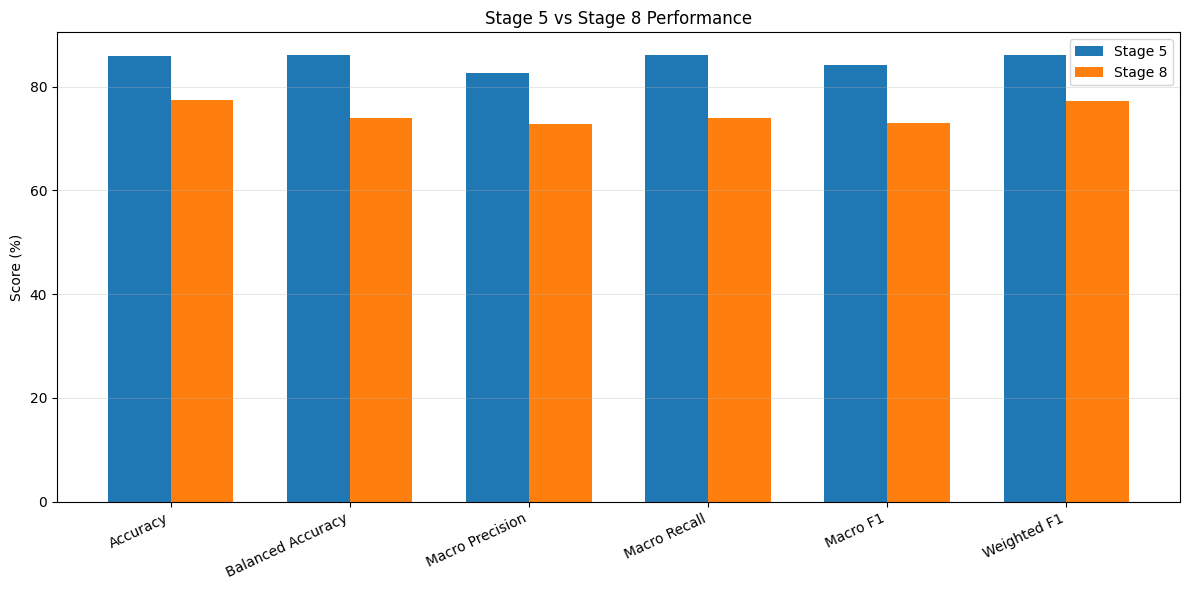

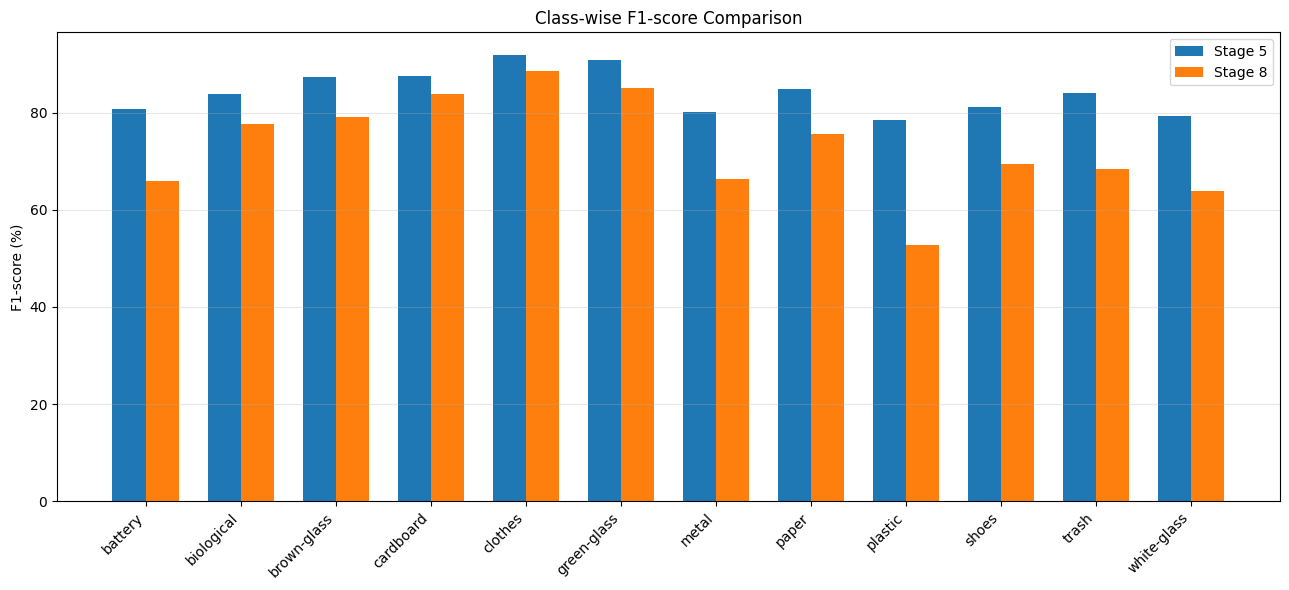


최종 모델 선정 결과
최종 모델: Stage 5 Improved CNN
Accuracy: 85.9536%
Balanced Accuracy: 86.1776%
Macro F1: 84.1724%
Weighted F1: 86.0836%

Stage 8과 비교하여 Stage 5를 최종 모델로 선택했습니다.

===== 9단계 완료 =====


In [ ]:

# =========================================================
# 9단계: Stage 5 vs Stage 8 최종 성능 비교 및 최종 모델 선정
# =========================================================

import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ---------------------------------------------------------
# 0. 모델 및 데이터 확인
# ---------------------------------------------------------

assert "best_model_stage5" in globals(), \
    "5단계를 먼저 실행하세요."

assert "stage8_model" in globals(), \
    "8단계를 먼저 실행하세요."

assert "test_loader" in globals(), \
    "테스트 데이터(test_loader)를 먼저 준비하세요."


# ---------------------------------------------------------
# 1. 테스트 평가 함수
# ---------------------------------------------------------

def evaluate_model_stage9(model, loader):

    model.eval()

    labels_all = []
    preds_all = []
    probs_all = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = probabilities.argmax(dim=1)

            labels_all.extend(labels.cpu().numpy())
            preds_all.extend(predictions.cpu().numpy())
            probs_all.extend(probabilities.cpu().numpy())

    return (
        np.array(labels_all),
        np.array(preds_all),
        np.array(probs_all)
    )


# ---------------------------------------------------------
# 2. Stage 5 모델 평가
# ---------------------------------------------------------

print("=" * 60)
print("Stage 5 모델 평가 중...")
print("=" * 60)

best_model_stage5.eval()

y_true_5, y_pred_5, y_prob_5 = evaluate_model_stage9(
    best_model_stage5,
    test_loader
)


# ---------------------------------------------------------
# 3. Stage 8 모델 평가
# ---------------------------------------------------------

print("\n" + "=" * 60)
print("Stage 8 모델 평가 중...")
print("=" * 60)

stage8_model.eval()

y_true_8, y_pred_8, y_prob_8 = evaluate_model_stage9(
    stage8_model,
    test_loader
)


# 동일한 테스트 데이터인지 확인

assert np.array_equal(y_true_5, y_true_8), (
    "두 모델의 테스트 정답 데이터가 일치하지 않습니다."
)


# ---------------------------------------------------------
# 4. 평가 지표 계산 함수
# ---------------------------------------------------------

def calculate_metrics_stage9(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(
            y_true, y_pred
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),

        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    }


metrics_5 = calculate_metrics_stage9(
    y_true_5,
    y_pred_5
)

metrics_8 = calculate_metrics_stage9(
    y_true_8,
    y_pred_8
)


# ---------------------------------------------------------
# 5. Stage 5와 Stage 8 성능 비교표
# ---------------------------------------------------------

comparison_df = pd.DataFrame(
    {
        "Stage 5": metrics_5,
        "Stage 8": metrics_8
    }
)

# 두 모델의 성능 차이를 퍼센트포인트(%p)로 계산
comparison_df["Difference (%p)"] = (
    comparison_df["Stage 8"] -
    comparison_df["Stage 5"]
) * 100


print("\n" + "=" * 70)
print("Stage 5 vs Stage 8 최종 성능 비교")
print("=" * 70)

# 성능 지표는 백분율로 표시하고,
# Difference는 이미 %p 단위이므로 다시 100을 곱하지 않음.

display(
    comparison_df.style.format({
        "Stage 5": "{:.4%}",
        "Stage 8": "{:.4%}",
        "Difference (%p)": "{:+.4f}%p"
    })
)


# ---------------------------------------------------------
# 6. Stage 5 클래스별 성능 평가
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("Stage 5 클래스별 성능")
print("=" * 70)

print(
    classification_report(
        y_true_5,
        y_pred_5,
        target_names=classes,
        digits=4,
        zero_division=0
    )
)


# ---------------------------------------------------------
# 7. Stage 8 클래스별 성능 평가
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("Stage 8 클래스별 성능")
print("=" * 70)

print(
    classification_report(
        y_true_8,
        y_pred_8,
        target_names=classes,
        digits=4,
        zero_division=0
    )
)


# ---------------------------------------------------------
# 8. 전체 성능 비교 그래프
# ---------------------------------------------------------

metric_names = list(metrics_5.keys())

x = np.arange(len(metric_names))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    [metrics_5[m] * 100 for m in metric_names],
    width,
    label="Stage 5"
)

plt.bar(
    x + width / 2,
    [metrics_8[m] * 100 for m in metric_names],
    width,
    label="Stage 8"
)

plt.xticks(
    x,
    metric_names,
    rotation=25,
    ha="right"
)

plt.ylabel("Score (%)")
plt.title("Stage 5 vs Stage 8 Performance")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULT_DIR,
        "13_stage5_vs_stage8.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ---------------------------------------------------------
# 9. 클래스별 F1-score 비교 그래프
# ---------------------------------------------------------

report_5 = classification_report(
    y_true_5,
    y_pred_5,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_8 = classification_report(
    y_true_8,
    y_pred_8,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

f1_5 = [
    report_5[c]["f1-score"] * 100
    for c in classes
]

f1_8 = [
    report_8[c]["f1-score"] * 100
    for c in classes
]

x = np.arange(len(classes))

plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    f1_5,
    width,
    label="Stage 5"
)

plt.bar(
    x + width / 2,
    f1_8,
    width,
    label="Stage 8"
)

plt.xticks(
    x,
    classes,
    rotation=45,
    ha="right"
)

plt.ylabel("F1-score (%)")
plt.title("Class-wise F1-score Comparison")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULT_DIR,
        "14_classwise_f1_comparison.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ---------------------------------------------------------
# 10. 성능 비교 결과 저장
# ---------------------------------------------------------

comparison_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "stage5_vs_stage8_comparison.csv"
    ),
    encoding="utf-8-sig"
)


# 모델별 예측 결과 저장

np.savez(
    os.path.join(
        RESULT_DIR,
        "stage9_predictions.npz"
    ),
    y_true=y_true_5,
    stage5_pred=y_pred_5,
    stage5_prob=y_prob_5,
    stage8_pred=y_pred_8,
    stage8_prob=y_prob_8
)


# ---------------------------------------------------------
# 11. 최종 모델 선정
# ---------------------------------------------------------

# Stage 5가 Stage 8보다 테스트 성능이 높으므로
# Stage 5 모델을 최종 모델로 선정

final_model = best_model_stage5

final_model.eval()

print("\n" + "=" * 60)
print("최종 모델 선정 결과")
print("=" * 60)

print("최종 모델: Stage 5 Improved CNN")

print(
    "Accuracy:",
    f"{metrics_5['Accuracy'] * 100:.4f}%"
)

print(
    "Balanced Accuracy:",
    f"{metrics_5['Balanced Accuracy'] * 100:.4f}%"
)

print(
    "Macro F1:",
    f"{metrics_5['Macro F1'] * 100:.4f}%"
)

print(
    "Weighted F1:",
    f"{metrics_5['Weighted F1'] * 100:.4f}%"
)

print("\nStage 8과 비교하여 Stage 5를 최종 모델로 선택했습니다.")

print("\n===== 9단계 완료 =====")


최종 모델 저장 완료
파일 위치: /content/garbage_classification_results/final_garbage_classification_model.pth
최종 모델: Stage 5
클래스 수: 12
이미지 크기: 160
Colab 모델 파일: /content/final_garbage_classification_model.pth

===== 실제 쓰레기 이미지 분류 =====


Saving 음쓰1.jpg to 음쓰1 (3).jpg

===== 예측 결과 =====
1위: biological (73.11%)
2위: shoes (6.54%)
3위: white-glass (4.00%)


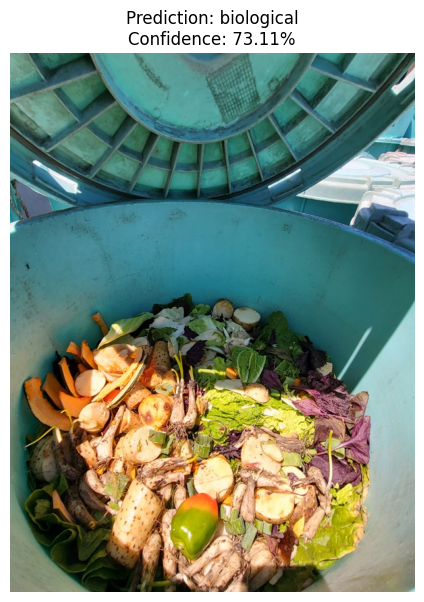


10단계 전체 완료
최종 모델: /content/garbage_classification_results/final_garbage_classification_model.pth
최종 모델 단계: Stage 5
모델 저장 및 실제 이미지 분류 준비 완료


In [ ]:

# =========================================================
# 10단계: 최종 모델 저장 및 실제 이미지 분류
# =========================================================

import os
import shutil
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms


# ---------------------------------------------------------
# 1. 최종 모델 확인
# ---------------------------------------------------------

# 9단계에서 선정한 Stage 5 모델 사용

assert "best_model_stage5" in globals(), \
    "5단계를 먼저 실행하세요."

assert "final_model" in globals(), \
    "9단계를 먼저 실행하세요."

final_model = best_model_stage5

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

final_model = final_model.to(device)
final_model.eval()


# ---------------------------------------------------------
# 2. 최종 모델 저장 파일 구성
# ---------------------------------------------------------

final_checkpoint = {

    "state_dict": {
        key: value.detach().cpu()
        for key, value in final_model.state_dict().items()
    },

    "classes": list(classes),

    "num_classes": len(classes),

    "image_size": IMAGE_SIZE,

    "mean": list(MEAN),

    "std": list(STD),

    "model_name": "ImprovedGarbageCNN",

    "final_stage": 5
}


# ---------------------------------------------------------
# 3. 최종 모델 저장
# ---------------------------------------------------------

FINAL_MODEL_PATH = os.path.join(
    RESULT_DIR,
    "final_garbage_classification_model.pth"
)

torch.save(
    final_checkpoint,
    FINAL_MODEL_PATH
)


print("=" * 60)
print("최종 모델 저장 완료")
print("=" * 60)

print("파일 위치:", FINAL_MODEL_PATH)
print("최종 모델: Stage 5")
print("클래스 수:", len(classes))
print("이미지 크기:", IMAGE_SIZE)


# ---------------------------------------------------------
# 4. Google Colab 모델 파일 복사
# ---------------------------------------------------------

COLAB_MODEL_PATH = "/content/final_garbage_classification_model.pth"

if os.path.isdir("/content"):

    shutil.copy2(
        FINAL_MODEL_PATH,
        COLAB_MODEL_PATH
    )

    print(
        "Colab 모델 파일:",
        COLAB_MODEL_PATH
    )


# ---------------------------------------------------------
# 5. 이미지 전처리 정의
# ---------------------------------------------------------

inference_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=MEAN,
        std=STD
    )
])


# ---------------------------------------------------------
# 6. 이미지 분류 함수
# ---------------------------------------------------------

def predict_garbage_image(
    image_path,
    model=None,
    top_k=3
):

    # 기본적으로 최종 Stage 5 모델 사용

    if model is None:
        model = final_model

    model.eval()

    # 이미지 불러오기

    image = Image.open(
        image_path
    ).convert("RGB")

    # 이미지 전처리

    input_tensor = inference_transform(image)

    input_tensor = input_tensor.unsqueeze(0).to(device)

    # 모델 예측

    with torch.no_grad():

        outputs = model(input_tensor)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        top_probabilities, top_indices = torch.topk(
            probabilities,
            k=min(top_k, len(classes)),
            dim=1
        )

    # CPU로 변환

    top_probabilities = (
        top_probabilities[0].cpu().numpy()
    )

    top_indices = (
        top_indices[0].cpu().numpy()
    )

    # 예측 결과 정리

    results = []

    for probability, index in zip(
        top_probabilities,
        top_indices
    ):

        results.append({

            "class": classes[int(index)],

            "probability": float(probability)

        })

    return image, results


# ---------------------------------------------------------
# 7. 이미지 업로드 및 분류
# ---------------------------------------------------------

print("\n===== 실제 쓰레기 이미지 분류 =====")

try:

    from google.colab import files

    uploaded = files.upload()

    if uploaded:

        image_path = next(
            iter(uploaded.keys())
        )

        image, prediction_results = predict_garbage_image(
            image_path,
            top_k=3
        )

        print("\n===== 예측 결과 =====")

        for rank, result in enumerate(
            prediction_results,
            start=1
        ):

            print(
                f"{rank}위: {result['class']} "
                f"({result['probability'] * 100:.2f}%)"
            )

        # 이미지 및 예측 결과 시각화

        plt.figure(figsize=(7, 7))

        plt.imshow(image)

        plt.axis("off")

        plt.title(
            f"Prediction: {prediction_results[0]['class']}\n"
            f"Confidence: "
            f"{prediction_results[0]['probability'] * 100:.2f}%"
        )

        plt.show()

    else:

        print("업로드된 이미지가 없습니다.")


except ImportError:

    print(
        "Colab이 아닌 환경입니다.\n"
        "아래 함수를 사용하여 이미지를 분류할 수 있습니다."
    )

    print(
        "predict_garbage_image('이미지파일경로')"
    )


# ---------------------------------------------------------
# 8. 최종 완료
# ---------------------------------------------------------

print("\n" + "=" * 60)
print("10단계 전체 완료")
print("=" * 60)

print("최종 모델:", FINAL_MODEL_PATH)
print("최종 모델 단계: Stage 5")
print("모델 저장 및 실제 이미지 분류 준비 완료")
